# IPC : où les prix vont-ils monter le mois prochain ?

Mini-projet « Processus décisionnel Big Data » (5e année IA et Data).
Ce notebook déroule **tout le pipeline** sur les vraies données, dans l'ordre, et commente chaque choix.

**Question décisionnelle.** Un responsable public du suivi des prix (ministère du Commerce, wilaya) veut savoir,
un mois à l'avance, *dans quelles villes et sur quels produits les prix vont monter le plus*, pour envoyer
les contrôles ou les aides en priorité.

**Données.** HCP, « Indice des prix à la consommation (Mensuel) (Base 100 2017) », publié sur data.gov.ma :
https://data.gov.ma/data/fr/dataset/data_i4166

| Étape | Technologie | Ce qu'elle produit |
|---|---|---|
| 1. Collecte | Python (pandas) | 116 CSV, un par publication mensuelle |
| 2. Flux simulé + ingestion | Spark Structured Streaming | couche **bronze** + suivi en direct (variations, alertes) |
| 3. Prétraitement | Spark SQL | couches **silver** (nettoyé) et **gold** (agrégats, variables du modèle) |
| 4. Machine learning | Spark MLlib | prévision du mois prochain + groupes de villes |
| 5. Restitution | FastAPI + React | application décisionnelle (3 pages) |

**Le code exécuté ici est celui des scripts du projet** (`scripts/`, `spark/`) : le notebook les importe et affiche
leur code source avant de les lancer. Il n'y a donc qu'une seule version du pipeline.

**Lancement** (environ 15 min sous Windows) : Python 3.11 avec `requirements.txt` et `notebooks/requirements.txt`,
Java 17 (`JAVA_HOME`), et sous Windows `HADOOP_HOME` (winutils) pour écrire du Parquet.
Ouvrir avec `.venv\Scripts\python -m jupyterlab` (pas `jupyter lab`, qui peut prendre un autre Python du PC), puis *Run All*.
Le notebook refait les données locales dans `data/` (les données Docker, dans leur volume, ne sont pas touchées).

In [1]:
import importlib
import inspect
import os
import shutil
import subprocess
import sys
import textwrap
import time
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Code, display
from matplotlib.ticker import FuncFormatter

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for dossier in (RACINE, RACINE / "scripts", RACINE / "spark"):
    sys.path.insert(0, str(dossier))

# Bon environnement, vérifié tout de suite (sinon le flux peut se bloquer sans message clair) :
# Python 3.11 avec PySpark 3.5 (le venv du projet, pas un autre Python du PC), et Java 17 pour Spark
import pyspark
assert sys.version_info[:2] == (3, 11) and pyspark.__version__.startswith("3.5"), (
    f"Noyau {sys.executable} : Python {sys.version.split()[0]}, PySpark {pyspark.__version__}. "
    "Lancer Jupyter avec le Python du venv : .venv\Scripts\python -m jupyterlab")
# Le Java que Spark lancera est celui de JAVA_HOME
java = Path(os.environ["JAVA_HOME"]) / "bin" / "java" if "JAVA_HOME" in os.environ else "java"
version_java = subprocess.run([str(java), "-version"], capture_output=True, text=True).stderr
print(version_java.splitlines()[0])
assert '"17.' in version_java, "Spark 3.5 a besoin de Java 17 : faire pointer JAVA_HOME vers un JDK 17."

from config import BRONZE, FICHE_URL, GOLD, LANDING, STREAM_IN
from commun import SCHEMA_CSV, creer_spark, enrichir
from pyspark.sql import functions as F

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)


def montrer(*fonctions):
    """Affiche le code source exact (pris dans les scripts du projet) de ce qui va être exécuté."""
    for fonction in fonctions:
        display(Code(inspect.getsource(fonction), language="python"))


# Graphiques : palette de l'application (mode clair), validée pour le daltonisme
COULEURS = {"s1": "#0d9488", "s2": "#be185d", "s3": "#65a30d", "alerte": "#ea580c", "gris": "#94a3b8"}
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7ecf3", "axes.axisbelow": True, "font.size": 10})
en_pourcent = FuncFormatter(lambda v, _: f"{v:g} %".replace(".", ","))

spark = creer_spark("ipc-notebook")
print("Spark", spark.version, "| Python", sys.version.split()[0])

openjdk version "17.0.18" 2026-01-20


Spark 3.5.10 | Python 3.11.18


## 1. Collecte : le fichier du HCP découpé en publications mensuelles

Le fichier est au **format large** : une ligne par (ville, produit) et une colonne par mois, du plus récent au plus
ancien, avec des libellés français (`Juill-2026`). Pour simuler un flux réaliste, on le découpe en **un CSV par mois**
(`ipc_AAAA_MM.csv`, format long `ville, produit, mois, indice`) : un fichier = une publication mensuelle du HCP.

In [2]:
collecte = importlib.import_module("01_collecte")
print("Fiche :", FICHE_URL)
collecte.telecharger()                       # ne retélécharge pas si le fichier est déjà dans data/raw
long, colonnes_mois = collecte.lire_format_long()
print(f"Format large : {len(colonnes_mois)} colonnes de mois, de {colonnes_mois[-1]} à {colonnes_mois[0]}")
long.head()

Fiche : https://data.gov.ma/data/fr/dataset/data_i4166
Fichier déjà présent : C:\Users\pc\Documents\ipc-bigdata\data\raw\i_i4166_data.xlsx


C:\Users\pc\Documents\ipc-bigdata\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Format large : 116 colonnes de mois, de Janv-2017 à Août-2026


,ville,produit,mois,indice
0,National,(GR) GENERAL,Août-2026,119.6
1,National,(01) PRODUITS ALIMENTAIRES ET BOISSONS NON ALC...,Août-2026,125.8
2,National,(011) PRODUITS ALIMENTAIRES,Août-2026,126.3
3,National,(0111) PAIN ET CEREALES,Août-2026,117.5
4,National,(0112) VIANDE,Août-2026,141.3


In [3]:
montrer(collecte.ecrire_csv_mensuels)
collecte.ecrire_csv_mensuels(long)
collecte.controler()   # relit les CSV écrits et vérifie les chiffres clés contre le fichier brut

def ecrire_csv_mensuels(long):
    LANDING.mkdir(parents=True, exist_ok=True)
    for libelle, publication in long.groupby("mois", sort=False):
        annee, mois = mois_vers_annee_mois(libelle)
        publication.to_csv(LANDING / f"ipc_{annee}_{mois:02d}.csv", index=False, encoding="utf-8")


Fichiers CSV       : 116  (ipc_2017_01.csv -> ipc_2026_08.csv)
Observations       : 318,304
Valeurs manquantes : 0
Zones / produits   : 19 / 148
Séries             : 2,744


Lignes par fichier : [2744]

Inflation nationale sur 12 mois (indice général) :
  01/2018 :   2.01 %   attendu   2.01 %   OK
  02/2023 :  10.08 %   attendu  10.08 %   OK
  08/2026 :  -0.33 %   attendu  -0.33 %   OK


**Résultat.** 116 mois (janvier 2017 à août 2026), 19 zones (National + 18 villes), 148 postes, 2 744 séries,
318 304 observations, **aucune valeur manquante**. L'inflation nationale sur 12 mois recalculée à partir du fichier
retrouve les chiffres publiés : 2,01 % en janvier 2018, 10,08 % en février 2023 (pic), -0,33 % en août 2026.

## 2. Ingestion en temps réel : Spark Structured Streaming

**Producteur (flux simulé).** Il copie les CSV un par un dans `data/stream_in/`. Deux pièges réglés :
- Spark lit les fichiers d'un dossier **par date de modification** : le producteur fixe des dates croissantes
  (`os.utime`), sinon des mois publiés en même temps seraient lus dans le désordre ;
- chaque fichier est écrit sous un nom caché puis **renommé** (opération atomique) : Spark ne lit jamais un fichier à moitié copié.

In [4]:
producteur = importlib.import_module("02_producteur_flux")
streaming = importlib.import_module("03_streaming")
montrer(producteur.publier)

# Départ propre : on efface le flux précédent (checkpoint, bronze, suivi, journal).
for dossier in (streaming.CHECKPOINT, BRONZE, streaming.SUIVI, streaming.JOURNAL, STREAM_IN):
    shutil.rmtree(dossier, ignore_errors=True)
STREAM_IN.mkdir(parents=True)

# On publie d'abord l'historique (janvier 2017 à décembre 2025) ; les 8 mois de 2026 arriveront ensuite, « en direct ».
publications = sorted(LANDING.glob("ipc_*.csv"))
historique, mois_2026 = publications[:-8], publications[-8:]
derniere_date = 0
for source in historique:
    derniere_date = producteur.publier(source, derniere_date)
print(len(historique), "publications dans", STREAM_IN, f"({historique[0].name} -> {historique[-1].name})")

def publier(source, derniere_date_modif):
    temporaire = STREAM_IN / f".{source.name}.tmp"
    shutil.copyfile(source, temporaire)
    date_modif = max(time.time(), derniere_date_modif + 1)
    os.utime(temporaire, (date_modif, date_modif))
    os.replace(temporaire, STREAM_IN / source.name)  # renommage atomique, garde la date de modification
    return date_modif

108 publications dans C:\Users\pc\Documents\ipc-bigdata\data\stream_in (ipc_2017_01.csv -> ipc_2025_12.csv)


**Lecture en flux.** Structured Streaming surveille le dossier :
- **schéma explicite** (obligatoire en streaming : Spark ne peut pas deviner le schéma de fichiers à venir) ;
- `maxFilesPerTrigger` : nombre de fichiers par micro-batch. En direct (application), **1 fichier = 1 mois = 1 micro-batch**,
  comme une vraie publication mensuelle. Pour **rattraper l'historique** au démarrage, on autorise 12 fichiers (un an)
  par lot : c'est ce que ferait un vrai flux qui démarre sur 9 ans de données, et c'est bien plus rapide ;
- `enrichir` (Spark SQL, `spark/commun.py`) convertit `Juill-2026` en date et extrait du libellé produit
  le code, le niveau (général, division, groupe, sous-groupe) et la division ;
- un **checkpoint** retient les fichiers déjà traités : après une panne, le flux reprend sans doublon.

In [5]:
montrer(enrichir)

def enrichir(df):
    for nom, expression in COLONNES_ENRICHIES.items():
        df = df.withColumn(nom, F.expr(expression))
    return df

**Traitement de chaque micro-batch** (`foreachBatch`) :
1. couche **bronze** : les données brutes enrichies, en Parquet partitionné par mois. L'écrasement est
   *dynamique* : rejouer un lot réécrit son mois, sans doublon ;
2. **suivi** pour chaque ville, l'indice général et les 12 divisions (247 séries) :
   variation mensuelle = indice(m) / indice(m-1) - 1, glissement annuel = indice(m) / indice(m-12) - 1,
   **alerte** = glissement annuel > 4 %. Les 12 premiers mois n'ont pas de glissement : l'alerte vaut `False`, pas `null` ;
3. une ligne de **journal** (durée du lot, lignes, alertes) que l'application affiche dans « Santé du pipeline ».

In [6]:
montrer(streaming.traiter_lot)

def traiter_lot(lot, numero_lot):
    debut = time.perf_counter()
    spark = lot.sparkSession
    lot.persist()
    mois_du_lot = [ligne.date for ligne in lot.select("date").distinct().collect()]
    if not mois_du_lot:
        return
    # Contrôle qualité : un libellé de mois ou un code produit inconnu doit arrêter le flux, pas passer en silence
    invalides = lot.filter(F.col("date").isNull() | F.col("niveau").isNull()).count()
    if invalides:
        raise ValueError(f"{invalides} lignes avec un mois ou un code produit illisible (lot {numero_lot})")

    # 1. Bronze, partitionné par mois (écrasement dynamique : rejouer un lot ne crée pas de doublons)
    lot.write.mode("overwrite").partitionBy("date").parquet(BRONZE.as_posix())

    # 2. Suivi : il faut le mois courant, le mois précédent et le même mois l'an dernier
    dates_utiles = [ligne.d for ligne in lot.select(F.explode(F.array(
        "date", F.add_months("date", -1), F.add_months("date", -12))).alias("d")).distinct().collect()]
    historique = (
        spark.read.parquet(BRONZE.as_posix())
        .filter(F.col("date").isin(dates_utiles))                   # ne lit que les partitions utiles
        .filter(F.col("niveau").isin("general", "division"))        # indice général + 12 divisions
        .select("ville", "code", "libelle", "date", "indice")
    )
    precedent = historique.select("ville", "code", F.add_months("date", 1).alias("date"),
                                  F.col("indice").alias("indice_mois_precedent"))
    an_dernier = historique.select("ville", "code", F.add_months("date", 12).alias("date"),
                                   F.col("indice").alias("indice_an_dernier"))
    suivi = (
        historique.filter(F.col("date").isin(mois_du_lot))
        .join(precedent, ["ville", "code", "date"], "left")
        .join(an_dernier, ["ville", "code", "date"], "left")
        .withColumn("variation_mensuelle",
                    F.round((F.col("indice") / F.col("indice_mois_precedent") - 1) * 100, 2))
        .withColumn("glissement_annuel",
                    F.round((F.col("indice") / F.col("indice_an_dernier") - 1) * 100, 2))
        .withColumn("alerte", F.coalesce(F.col("glissement_annuel") > SEUIL_ALERTE, F.lit(False)))
        .drop("indice_mois_precedent", "indice_an_dernier")
        .cache()
    )
    suivi.write.mode("overwrite").partitionBy("date").parquet(SUIVI.as_posix())

    # Journal du micro-batch
    national = suivi.filter("ville = 'National' AND code = 'GR'").first()
    nb_alertes = suivi.filter("alerte").count()
    nb_lignes, nb_series = lot.count(), suivi.count()
    glissement = "  n/d " if national.glissement_annuel is None else f"{national.glissement_annuel:6.2f}"
    print(f"[lot {numero_lot:3d}] {national.date:%Y-%m} : {nb_lignes:,} lignes | "
          f"inflation nationale {glissement} % | {nb_alertes:3d} alertes / {nb_series} séries", flush=True)
    # Journal : la fin est en secondes depuis 1970 (pas de fuseau horaire à gérer entre conteneurs et navigateur).
    # Un lot rejoué après une panne ajoute une 2e ligne au même numéro : l'API garde la plus récente.
    duree = round(time.perf_counter() - debut, 2)
    spark.createDataFrame(
        [(numero_lot, national.date, nb_lignes, nb_alertes, nb_series, duree, time.time())],
        "numero_lot LONG, mois DATE, lignes LONG, alertes LONG, series LONG, duree_s DOUBLE, fin DOUBLE",
    ).coalesce(1).write.mode("append").parquet(JOURNAL.as_posix())
    suivi.unpersist()
    lot.unpersist()

In [7]:
def lancer_flux(fichiers_par_lot):
    # availableNow : traite les fichiers arrivés depuis le dernier passage (checkpoint), puis s'arrête.
    # L'application utilise le même code avec un déclencheur toutes les 2 s, qui attend les publications.
    flux = (
        spark.readStream.schema(SCHEMA_CSV)
        .option("header", True)
        .option("maxFilesPerTrigger", fichiers_par_lot)
        .csv(STREAM_IN.as_posix())
    )
    flux = (enrichir(flux)
            .withColumn("fichier", F.element_at(F.split(F.input_file_name(), "/"), -1))
            .withColumn("date_ingestion", F.current_timestamp()))
    debut, console = time.time(), StringIO()
    with redirect_stdout(console):  # traiter_lot écrit une ligne par lot : on la récupère pour l'afficher
        requete = (flux.writeStream.foreachBatch(streaming.traiter_lot)
                   .option("checkpointLocation", streaming.CHECKPOINT.as_posix())  # retient les fichiers déjà lus
                   .trigger(availableNow=True).start())
        requete.awaitTermination()
    print(f"{len(requete.recentProgress)} micro-batches en {time.time() - debut:.0f} s")
    print(console.getvalue())


# 1. Rattrapage de l'historique : 12 fichiers (un an) par micro-batch
lancer_flux(fichiers_par_lot=12)

9 micro-batches en 175 s
[lot   0] 2017-12 : 32,928 lignes | inflation nationale   n/d  % |   0 alertes / 2964 séries
[lot   1] 2018-12 : 32,928 lignes | inflation nationale   0.20 % | 467 alertes / 2964 séries
[lot   2] 2019-12 : 32,928 lignes | inflation nationale   1.08 % | 470 alertes / 2964 séries
[lot   3] 2020-09 : 32,928 lignes | inflation nationale   1.37 % | 118 alertes / 2964 séries
[lot   4] 2021-11 : 32,928 lignes | inflation nationale   2.63 % | 406 alertes / 2964 séries
[lot   5] 2022-12 : 32,928 lignes | inflation nationale   8.34 % | 1205 alertes / 2964 séries
[lot   6] 2023-09 : 32,928 lignes | inflation nationale   4.86 % | 1266 alertes / 2964 séries
[lot   7] 2024-10 : 32,928 lignes | inflation nationale   0.67 % | 295 alertes / 2964 séries
[lot   8] 2025-09 : 32,928 lignes | inflation nationale   0.42 % | 231 alertes / 2964 séries



**Fonctionnement en direct.** Le producteur publie maintenant les 8 mois de 2026. Le flux est relancé avec le **même
checkpoint** et **un fichier par micro-batch** : il ne relit pas l'historique, il ne traite que les 8 nouveaux fichiers,
un mois par lot. C'est ce qui se passe dans l'application à chaque publication du HCP.

In [8]:
for source in mois_2026:
    derniere_date = producteur.publier(source, derniere_date)
lancer_flux(fichiers_par_lot=1)

8 micro-batches en 112 s
[lot   9] 2026-01 : 2,744 lignes | inflation nationale  -0.75 % |  14 alertes / 247 séries
[lot  10] 2026-02 : 2,744 lignes | inflation nationale  -0.58 % |  14 alertes / 247 séries
[lot  11] 2026-03 : 2,744 lignes | inflation nationale   0.92 % |  15 alertes / 247 séries
[lot  12] 2026-04 : 2,744 lignes | inflation nationale   1.67 % |  37 alertes / 247 séries
[lot  13] 2026-05 : 2,744 lignes | inflation nationale   1.18 % |  41 alertes / 247 séries
[lot  14] 2026-06 : 2,744 lignes | inflation nationale   0.33 % |  39 alertes / 247 séries
[lot  15] 2026-07 : 2,744 lignes | inflation nationale  -0.59 % |  33 alertes / 247 séries
[lot  16] 2026-08 : 2,744 lignes | inflation nationale  -0.33 % |  42 alertes / 247 séries



In [9]:
streaming.controler(spark)   # bronze et suivi relus sur disque + contrôle des chiffres clés (assert)
journal = spark.read.parquet(streaming.JOURNAL.as_posix()).toPandas().sort_values("numero_lot")
print(f"\nJournal : {len(journal)} lots, {journal.lignes.sum():,} lignes, "
      f"durée médiane d'un lot {journal.duree_s.median():.2f} s")
journal.tail(3)


Bronze : 318,304 lignes, 116 mois


Postes par niveau : {'general': 1, 'sous-groupe': 92, 'division': 12, 'groupe': 43}


Suivi  : 28,652 lignes (247 séries), alertes nulles : 0


Alertes en février 2023 : 144
  inflation nationale 2018-01 :   2.01 %  (attendu 2.01)


  inflation nationale 2023-02 :  10.08 %  (attendu 10.08)
  inflation nationale 2026-08 :  -0.33 %  (attendu -0.33)



Journal : 17 lots, 318,304 lignes, durée médiane d'un lot 3.17 s


,numero_lot,mois,lignes,alertes,series,duree_s,fin
10,14,2026-06-01,2744,39,247,1.78,1.795732e+09
5,15,2026-07-01,2744,33,247,1.57,1.795732e+09
15,16,2026-08-01,2744,42,247,1.45,1.795732e+09


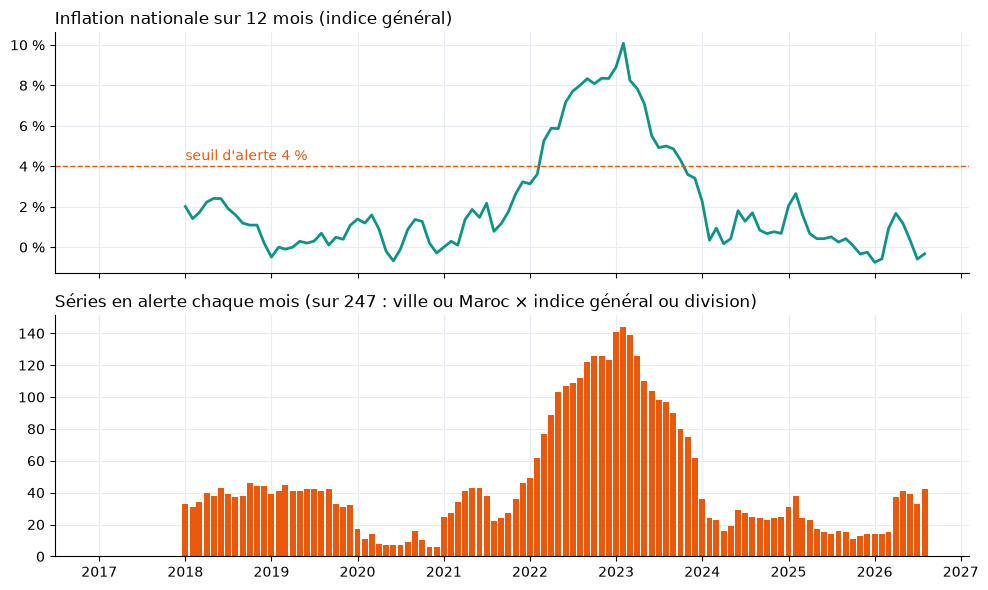

In [10]:
suivi = spark.read.parquet(streaming.SUIVI.as_posix())
national = suivi.filter("ville = 'National' AND code = 'GR' AND glissement_annuel IS NOT NULL") \
                .select("date", "glissement_annuel").orderBy("date").toPandas()
alertes = suivi.groupBy("date").agg(F.sum(F.col("alerte").cast("int")).alias("nb")).orderBy("date").toPandas()

figure, (haut, bas) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
haut.plot(national.date, national.glissement_annuel, color=COULEURS["s1"], linewidth=2)
haut.axhline(4, color=COULEURS["alerte"], linestyle="--", linewidth=1)
haut.text(national.date.iloc[0], 4.3, "seuil d'alerte 4 %", color=COULEURS["alerte"])
haut.set_title("Inflation nationale sur 12 mois (indice général)", loc="left")
haut.yaxis.set_major_formatter(en_pourcent)
bas.bar(alertes.date, alertes.nb, width=25, color=COULEURS["alerte"])
bas.set_title("Séries en alerte chaque mois (sur 247 : ville ou Maroc × indice général ou division)", loc="left")
figure.tight_layout()

**Lecture.** La vague d'inflation de 2022-2023 ressort nettement : jusqu'à **144 séries sur 247 en alerte en février 2023**,
quand l'inflation nationale atteignait 10,08 %. En août 2026, l'inflation nationale est retombée à -0,33 %,
mais **42 séries restent en alerte** : la moyenne nationale cache des hausses locales fortes (par exemple Settat,
restaurants et hôtels). C'est précisément ce que le responsable public doit voir.

## 3. Prétraitement avec Spark SQL : couches silver et gold

Tout est écrit en **SQL sur des vues temporaires** (`spark/04_spark_sql.py`) :
- **silver** : dédoublonnage (`ROW_NUMBER`, on garde la dernière ingestion), contrôles (indice positif, aucun mois
  manquant dans une série), puis variation mensuelle et glissement annuel de toutes les séries (`LAG`) ;
- **gold** : inflation annuelle avec classements des villes et des divisions (`RANK`), profil des villes
  (`PIVOT` : une ligne par ville, une colonne par division, entrée du KMeans), table des variables du modèle.

In [11]:
sql_spark = importlib.import_module("04_spark_sql")
sql_spark.spark = spark          # le script utilise une SparkSession globale
montrer(sql_spark.construire_silver)
sql_spark.construire_silver()

def construire_silver():
    spark.read.parquet(BRONZE.as_posix()).createOrReplaceTempView("bronze")

    # Nettoyage : un mois republié par le HCP (ou rejoué par le flux) ne garde que sa dernière version ;
    # on écarte les indices vides ou négatifs (aucun dans ce fichier, mais le flux pourrait en recevoir).
    sql("""
        CREATE OR REPLACE TEMP VIEW ipc_propre AS
        SELECT trim(ville) AS ville, code, libelle, niveau, division,
               date, year(date) AS annee, month(date) AS mois, indice
        FROM (
            SELECT *, ROW_NUMBER() OVER (PARTITION BY ville, produit, date
                                         ORDER BY date_ingestion DESC) AS version
            FROM bronze
            WHERE indice IS NOT NULL AND indice > 0 AND date IS NOT NULL
        )
        WHERE version = 1
    """)

    # LAG(…, 12) = « 12 lignes avant » : ce n'est le même mois de l'an dernier que si aucun mois ne manque.
    trous = valeur("""
        SELECT count(*) FROM (
            SELECT ville, code, count(*) AS nb_mois,
                   months_between(max(date), min(date)) + 1 AS nb_attendu
            FROM ipc_propre GROUP BY ville, code
        ) WHERE nb_mois <> nb_attendu
    """)
    assert trous == 0, f"{trous} séries ont des mois manquants"

    sql("""
        SELECT *,
               100 * (indice / LAG(indice, 1)  OVER serie - 1) AS variation_mensuelle,
               100 * (indice / LAG(indice, 12) OVER serie - 1) AS glissement_annuel
        FROM ipc_propre
        WINDOW serie AS (PARTITION BY ville, code ORDER BY date)
    """).write.mode("overwrite").parquet(SILVER_IPC.as_posix())

    # La suite lit la couche silver écrite (et non le calcul en mémoire)
    spark.read.parquet(SILVER_IPC.as_posix()).createOrReplaceTempView("silver")

In [12]:
montrer(sql_spark.construire_inflation_annuelle, sql_spark.construire_profil_villes)
sql_spark.construire_inflation_annuelle()
sql_spark.construire_profil_villes()

def construire_inflation_annuelle():
    # Inflation annuelle (définition du HCP) = moyenne des indices de l'année / moyenne de l'année d'avant - 1.
    # Seulement les années complètes (12 mois). Classements : villes entre elles, divisions entre elles.
    sql("""
        WITH moyennes AS (
            SELECT ville, code, libelle, annee, avg(indice) AS indice_moyen, count(*) AS nb_mois
            FROM silver WHERE niveau IN ('general', 'division')
            GROUP BY ville, code, libelle, annee
        ),
        inflation AS (
            SELECT a.ville, a.code, a.libelle, a.annee,
                   round(100 * (a.indice_moyen / b.indice_moyen - 1), 2) AS inflation
            FROM moyennes a
            JOIN moyennes b ON a.ville = b.ville AND a.code = b.code AND a.annee = b.annee + 1
            WHERE a.nb_mois = 12
        )
        SELECT *,
               CASE WHEN ville <> 'National' THEN
                   RANK() OVER (PARTITION BY code, annee, ville = 'National' ORDER BY inflation DESC)
               END AS rang_ville,
               CASE WHEN code <> 'GR' THEN
                   RANK() OVER (PARTITION BY ville, annee, code = 'GR' ORDER BY inflation DESC)
               END AS rang_division
        FROM inflation
    """).write.mode("overwrite").parquet(INFLATION_ANNUELLE.as_posix())
    spark.read.parquet(INFLATION_ANNUELLE.as_posix()).createOrReplaceTempView("inflation_annuelle")

def construire_profil_villes():
    # Une ligne par ville (sans National), une colonne par division : glissement annuel moyen sur la période.
    colonnes = ", ".join(f"'{code}' AS d{code}" for code in DIVISIONS)
    sql(f"""
        SELECT * FROM (
            SELECT ville, code, glissement_annuel FROM silver
            WHERE niveau = 'division' AND ville <> 'National' AND glissement_annuel IS NOT NULL
        )
        PIVOT (round(avg(glissement_annuel), 3) FOR code IN ({colonnes}))
        ORDER BY ville
    """).write.mode("overwrite").parquet(PROFIL_VILLES.as_posix())

**Table du modèle.** La cible est la **variation mensuelle du mois suivant, en %** (`LEAD`), jamais l'indice lui-même :
prédire l'indice donne un R² d'environ 0,99 en recopiant simplement le mois précédent, ce qui ne prouve rien.
Variables : variation du mois courant et des 2 mois précédents, glissement annuel, variation du même mois l'an dernier,
mois de l'année, ville, division, variation nationale de la division.
Le découpage suit **le temps, jamais le hasard** : entraînement 2018-2023, validation 2024, test 2025-2026 ;
le dernier mois connu (août 2026) est celui à prédire.

In [13]:
montrer(sql_spark.construire_variables_modele)
sql_spark.construire_variables_modele()
sql_spark.afficher_resultats()

def construire_variables_modele():
    # Pour chaque série (19 zones × indice général + 12 divisions) et chaque mois m :
    # on connaît m et le passé, on veut prédire la variation de m+1 (la cible).
    sql("""
        CREATE OR REPLACE TEMP VIEW series AS
        SELECT ville, code, libelle, date, variation_mensuelle, glissement_annuel,
               LAG(variation_mensuelle, 1)  OVER serie AS variation_m1,
               LAG(variation_mensuelle, 2)  OVER serie AS variation_m2,
               -- m+1 l'an dernier = m-11 : « même mois l'an dernier », aussi la 2e référence naïve
               LAG(variation_mensuelle, 11) OVER serie AS variation_meme_mois_an_dernier,
               LEAD(variation_mensuelle, 1) OVER serie AS cible
        FROM silver
        WHERE niveau IN ('general', 'division')
        WINDOW serie AS (PARTITION BY ville, code ORDER BY date)
    """)
    # Découpage dans le temps, selon le mois m où la prévision est faite (jamais aléatoire).
    # Le dernier mois connu n'a pas encore de cible : c'est la prévision réelle du mois prochain.
    sql("""
        SELECT s.ville, s.code, s.libelle, s.date, add_months(s.date, 1) AS date_cible,
               month(add_months(s.date, 1)) AS mois_cible,
               s.variation_mensuelle, s.variation_m1, s.variation_m2, s.glissement_annuel,
               s.variation_meme_mois_an_dernier,
               n.variation_mensuelle AS variation_nationale_division,
               s.cible,
               CASE WHEN s.date = (SELECT max(date) FROM silver) THEN 'a_predire'
                    WHEN year(s.date) <= 2023 THEN 'entrainement'
                    WHEN year(s.date) = 2024 THEN 'validation'
                    ELSE 'test' END AS ensemble
        FROM series s
        JOIN series n ON n.ville = 'National' AND n.code = s.code AND n.date = s.date
        WHERE s.date >= '2018-01-01'
    """).write.mode("overwrite").parquet(VARIABLES_MODELE.as_posix())
    spark.read.parquet(VARIABLES_MODELE.as_posix()).createOrReplaceTempView("variables_modele")


Silver : 318,304 lignes
Inflation sur 12 mois, contrôle :


+-------+----------+
|   mois|glissement|
+-------+----------+
|2018-01|      2.01|
|2023-02|     10.08|
|2026-08|     -0.33|
+-------+----------+

Inflation annuelle nationale (indice général) :
+-----+---------+
|annee|inflation|
+-----+---------+
| 2018|      1.6|
| 2019|     0.25|
| 2020|     0.62|
| 2021|      1.4|
| 2022|     6.66|
| 2023|     6.09|
| 2024|     0.99|
| 2025|      0.7|
+-----+---------+

2023 : les 5 villes les plus touchées (indice général) :


+----------+-----------+---------+
|rang_ville|      ville|inflation|
+----------+-----------+---------+
|         1| Al Hoceima|    10.07|
|         2|Béni Mellal|     8.81|
|         3| Errachidia|      8.1|
|         4|   Laâyoune|     7.62|
|         5|       Safi|     7.46|
+----------+-----------+---------+

2022 : les 3 divisions qui ont le plus augmenté au niveau national :
+-------------+----+-------------------------------------------------------+---------+
|rang_division|code|                                                libelle|inflation|
+-------------+----+-------------------------------------------------------+---------+
|            1|  07|                                             TRANSPORTS|    12.18|
|            2|  01|      PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES|    11.29|
|            3|  05|MEUBLES, ARTICLES DE MENAGE ET ENTRETIEN COURANT DU ...|     5.09|
+-------------+----+-------------------------------------------------------+---------+



Profil des villes : 18 villes x 12 divisions
+-----------+-----+-----+-----+-----+
|      ville|  d01|  d04|  d07|  d11|
+-----------+-----+-----+-----+-----+
|     Agadir|3.325|1.076|1.827|1.566|
| Al Hoceima| 4.06|0.883|2.604|2.242|
|Béni Mellal|3.241|1.248|3.897|3.125|
+-----------+-----+-----+-----+-----+
only showing top 3 rows

Table du modèle, par ensemble :


+------------+------+----------+----------+-------------+----------------+
|    ensemble|lignes|        de|         a|cible_moyenne|cible_ecart_type|
+------------+------+----------+----------+-------------+----------------+
|entrainement| 17784|2018-01-01|2023-12-01|        0.179|           1.061|
|  validation|  2964|2024-01-01|2024-12-01|        0.127|            0.73|
|        test|  4693|2025-01-01|2026-07-01|        0.102|           0.986|
|   a_predire|   247|2026-08-01|2026-08-01|         NULL|            NULL|
+------------+------+----------+----------+-------------+----------------+

Lignes avec une variable ou une cible vide (hors a_predire) : 0


In [14]:
annuelle = spark.read.parquet(sql_spark.INFLATION_ANNUELLE.as_posix())
annuelle.filter("ville = 'National' AND code = 'GR'").select("annee", "inflation").orderBy("annee").toPandas() \
    .set_index("annee").T.rename(index={"inflation": "inflation nationale annuelle (%)"})

annee,2018,2019,2020,2021,2022,2023,2024,2025
inflation nationale annuelle (%),1.6,0.25,0.62,1.4,6.66,6.09,0.99,0.7


In [15]:
# Classement des villes en 2023 (année du pic) : où l'indice général a le plus augmenté
annuelle.filter("annee = 2023 AND code = 'GR' AND rang_ville <= 5") \
    .select("rang_ville", "ville", "inflation").orderBy("rang_ville").toPandas()

,rang_ville,ville,inflation
0,1,Al Hoceima,10.07
1,2,Béni Mellal,8.81
2,3,Errachidia,8.10
3,4,Laâyoune,7.62
4,5,Safi,7.46


## 4. Machine learning avec Spark MLlib

### 4.1 Prévoir la variation des prix du mois suivant

- **Pipeline MLlib** : `StringIndexer` puis `OneHotEncoder` pour la ville, la division et le mois, `VectorAssembler`,
  puis le modèle. Trois familles : régression linéaire, Random Forest, GBT.
- **Réglages choisis sur la validation (2024)**, avec une petite grille écrite à la main (pas de validation croisée
  aléatoire, qui mélangerait passé et futur). Le modèle retenu est celui qui a la meilleure MAE en validation ;
  le test (2025-2026) n'est regardé qu'une fois, à la fin.
- **Évaluation** : MAE, RMSE, R², toujours **face à deux règles naïves** : « mois suivant = mois courant » et
  « même mois l'an dernier ». Plus une mesure utile à la décision : **part des 10 risques prédits qui sont parmi les
  10 plus fortes hausses réelles** du mois (sur 216 combinaisons ville × division ; le hasard ferait 10/216 = 5 %).

In [16]:
ml = importlib.import_module("05_mllib")
ml.spark = spark
montrer(ml.candidats, ml.pipeline, ml.part_top10)
donnees = spark.read.parquet(sql_spark.VARIABLES_MODELE.as_posix()).cache()
donnees.groupBy("ensemble").count().orderBy("ensemble").toPandas()

def candidats():
    """Petite grille par famille : (description des hyperparamètres, estimateur).
    Fonction et non constante : un estimateur MLlib ne peut être créé qu'une fois Spark démarré."""
    return {
        "Régression linéaire": [(f"regParam={r}", LinearRegression(labelCol="cible", regParam=r))
                                for r in (0.0, 0.01, 0.1)],
        "Random Forest": [(f"100 arbres, profondeur {p}",
                           RandomForestRegressor(labelCol="cible", numTrees=100, maxDepth=p, seed=42))
                          for p in (5, 8)],
        "GBT": [(f"100 itérations, profondeur {p}",
                 GBTRegressor(labelCol="cible", maxIter=100, maxDepth=p, stepSize=0.05, seed=42))
                for p in (3, 5)],
    }

def pipeline(estimateur):
    """Catégories -> index -> one-hot ; puis toutes les variables dans un seul vecteur ; puis le modèle."""
    index = [f"{c}_index" for c in CATEGORIES]
    vecteurs = [f"{c}_vecteur" for c in CATEGORIES]
    return Pipeline(stages=[
        StringIndexer(inputCols=CATEGORIES, outputCols=index, handleInvalid="keep"),
        OneHotEncoder(inputCols=index, outputCols=vecteurs),
        VectorAssembler(inputCols=NUMERIQUES + vecteurs, outputCol="features"),
        estimateur,
    ])

def part_top10(predictions, colonne, reel="cible"):
    """Chaque mois : combien des 10 plus fortes valeurs prédites sont dans les 10 plus fortes valeurs réelles."""
    combinaisons = predictions.filter("ville <> 'National' AND code <> 'GR'")
    par_mois = Window.partitionBy("date")
    return (
        combinaisons
        .withColumn("rang_predit", F.row_number().over(par_mois.orderBy(F.desc(colonne))))
        .withColumn("rang_reel", F.row_number().over(par_mois.orderBy(F.desc(reel))))
        .groupBy("date")
        .agg((F.sum(((F.col("rang_predit") <= 10) & (F.col("rang_reel") <= 10)).cast("int")) / 10)
             .alias("part"))
        .agg(F.avg("part")).first()[0]
    )

,ensemble,count
0,a_predire,247
1,entrainement,17784
2,test,4693
3,validation,2964


In [17]:
montrer(ml.regression)
debut = time.time()
famille_retenue = ml.regression(donnees)   # environ 4 min : 7 réglages x (validation + test) + modèle final
print(f"\nModèle retenu : {famille_retenue} ({time.time() - debut:.0f} s)")

def regression(donnees):
    entrainement = donnees.filter("ensemble = 'entrainement'")
    validation = donnees.filter("ensemble = 'validation'")
    test = donnees.filter("ensemble = 'test'")
    entrainement_validation = donnees.filter("ensemble IN ('entrainement', 'validation')")
    connues = donnees.filter("ensemble <> 'a_predire'")
    a_predire = donnees.filter("ensemble = 'a_predire'")

    metriques = []  # (modèle, paramètres, ensemble, mesures)
    for nom, colonne in REFERENCES.items():
        metriques.append((nom, "-", "validation", mesurer(validation, colonne)))
        metriques.append((nom, "-", "test", mesurer(test, colonne)))

    # 1. Hyperparamètres sur la validation, puis réentraînement sur 2018-2024 et mesure sur le test
    retenus = {}
    for famille, grille in candidats().items():
        essais = []
        for parametres, estimateur in grille:
            mae = RegressionEvaluator(labelCol="cible", metricName="mae").evaluate(
                pipeline(estimateur).fit(entrainement).transform(validation))
            print(f"  {famille:20s} {parametres:28s} MAE validation = {mae:.4f}", flush=True)
            essais.append((mae, parametres, estimateur))
        _, parametres, estimateur = min(essais, key=lambda essai: essai[0])
        metriques.append((famille, parametres, "validation",
                          mesurer(pipeline(estimateur).fit(entrainement).transform(validation))))
        modele = pipeline(estimateur).fit(entrainement_validation)
        predictions_test = modele.transform(test).cache()
        metriques.append((famille, parametres, "test", mesurer(predictions_test)))
        retenus[famille] = (parametres, estimateur, modele, predictions_test)

    # 2. Modèle retenu = meilleure MAE sur la VALIDATION (le test ne sert qu'à la note finale)
    mae_validation = {m: mesures["mae"] for m, _, ensemble, mesures in metriques if ensemble == "validation"}
    famille_retenue = min(retenus, key=lambda famille: mae_validation[famille])
    parametres, estimateur, modele, predictions_test = retenus[famille_retenue]

    table_metriques = spark.createDataFrame(
        [(m, p, e, mes["mae"], mes["rmse"], mes["r2"], mes["part_top10"], mes["part_top10_surprise"],
          m == famille_retenue) for m, p, e, mes in metriques],
        "modele STRING, parametres STRING, ensemble STRING, mae DOUBLE, rmse DOUBLE, r2 DOUBLE, "
        "part_top10 DOUBLE, part_top10_surprise DOUBLE, retenu BOOLEAN")
    table_metriques.write.mode("overwrite").parquet((GOLD / "metriques").as_posix())

    # 3. Erreur par division sur le test : où le modèle aide-t-il, où la règle naïve suffit-elle ?
    erreurs = predictions_test.withColumn("erreur_modele", F.abs(F.col("prediction") - F.col("cible")))
    for nom, colonne in REFERENCES.items():
        erreurs = erreurs.withColumn(f"erreur_{colonne}", F.abs(F.col(colonne) - F.col("cible")))
    (erreurs.groupBy("code", "libelle")
     .agg(F.avg("erreur_modele").alias("mae_modele"),
          F.avg("erreur_variation_mensuelle").alias("mae_naif_mois_courant"),
          F.avg("erreur_variation_meme_mois_an_dernier").alias("mae_naif_an_dernier"))
     .orderBy("code")
     .write.mode("overwrite").parquet((GOLD / "metriques_division").as_posix()))

    (predictions_test.select("ville", "code", "libelle", "date", "date_cible", "cible", "prediction",
                             F.col("variation_mensuelle").alias("naif_mois_courant"),
                             F.col("variation_meme_mois_an_dernier").alias("naif_an_dernier"))
     .write.mode("overwrite").parquet((GOLD / "predictions_test").as_posix()))

    # 4. Prévision réelle du mois prochain : modèle retenu réentraîné sur toutes les données connues
    modele_final = pipeline(estimateur).fit(connues)
    # Rangs seulement pour les combinaisons ville × division (National et indice général ne sont pas des lieux d'action)
    groupes_rang = Window.partitionBy(F.col("ville") == "National", F.col("code") == "GR")
    com

  Régression linéaire  regParam=0.0                 MAE validation = 0.4184


  Régression linéaire  regParam=0.01                MAE validation = 0.4177


  Régression linéaire  regParam=0.1                 MAE validation = 0.4126


  Random Forest        100 arbres, profondeur 5     MAE validation = 0.3705


  Random Forest        100 arbres, profondeur 8     MAE validation = 0.3655


  GBT                  100 itérations, profondeur 3 MAE validation = 0.3988


  GBT                  100 itérations, profondeur 5 MAE validation = 0.4197



Importance des variables (Random Forest) :
  mois_cible                       0.208
  code                             0.159
  variation_meme_mois_an_dernier   0.152
  variation_nationale_division     0.134
  glissement_annuel                0.114
  ville                            0.068
  variation_m1                     0.057
  variation_mensuelle              0.054
  variation_m2                     0.053

Modèle retenu : Random Forest (158 s)


,modele,parametres,mae,rmse,r2,part_top10,part_top10_surprise,retenu
0,Random Forest,"100 arbres, profondeur 8",0.405,0.878,0.207,0.232,0.374,True
1,GBT,"100 itérations, profondeur 3",0.407,0.872,0.217,0.205,0.363,False
2,Régression linéaire,regParam=0.1,0.446,0.940,0.090,0.168,0.342,False
3,Naïf : même mois l'an dernier,-,0.472,1.056,-0.148,0.216,NaN,False
4,Naïf : mois suivant = mois courant,-,0.573,1.284,-0.697,0.095,0.284,False


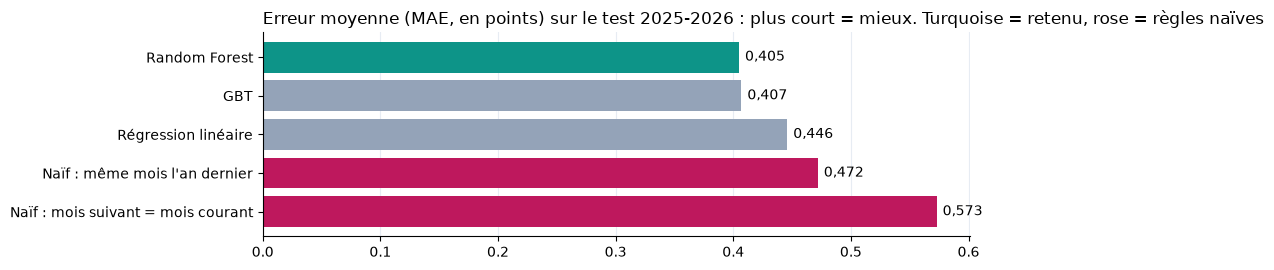

In [18]:
metriques = spark.read.parquet((GOLD / "metriques").as_posix()).filter("ensemble = 'test'").toPandas() \
    .sort_values("mae")[["modele", "parametres", "mae", "rmse", "r2", "part_top10", "part_top10_surprise", "retenu"]].round(3)
display(metriques.reset_index(drop=True))

figure, axe = plt.subplots(figsize=(10, 2.8))
couleurs = [COULEURS["s1"] if r else COULEURS["s2"] if m.startswith("Naïf") else COULEURS["gris"]
            for m, r in zip(metriques.modele, metriques.retenu)]
axe.barh(metriques.modele, metriques.mae, color=couleurs)
axe.invert_yaxis()
for y, mae in enumerate(metriques.mae):
    axe.text(mae + 0.005, y, f"{mae:.3f}".replace(".", ","), va="center")
axe.set_title("Erreur moyenne (MAE, en points) sur le test 2025-2026 : plus court = mieux. "
              "Turquoise = retenu, rose = règles naïves", loc="left")
axe.grid(axis="y", visible=False)
figure.tight_layout()

**Lecture honnête des résultats (test : prévisions de février 2025 à août 2026, jamais vues pendant le réglage).**
- Le **Random Forest** est retenu : MAE **0,405 point**, contre 0,472 pour la meilleure règle naïve
  (« même mois l'an dernier ») et 0,573 pour « mois suivant = mois courant ». Il se trompe donc **14 % de moins**
  que la meilleure règle simple.
- Le **R² reste faible (0,21)** : la variation d'un mois est très bruitée (soldes, fêtes, chocs ponctuels).
  Le modèle ne prédit pas le chiffre exact ; il aide à **classer** les risques.
- Pour la décision, la part du top 10 retrouvée est de **23 %**, presque cinq fois le hasard (5 %),
  mais à peine mieux que la règle « même mois l'an dernier » (22 %) : le gain du modèle sur le classement est modeste.

In [19]:
par_division = spark.read.parquet((GOLD / "metriques_division").as_posix()).toPandas().sort_values("code")
par_division["meilleure méthode"] = par_division[["mae_modele", "mae_naif_mois_courant", "mae_naif_an_dernier"]] \
    .idxmin(axis=1).map({"mae_modele": "modèle", "mae_naif_mois_courant": "mois courant",
                         "mae_naif_an_dernier": "même mois l'an dernier"})
par_division.round(3)[["code", "libelle", "mae_modele", "mae_naif_an_dernier", "mae_naif_mois_courant", "meilleure méthode"]]

,code,libelle,mae_modele,mae_naif_an_dernier,mae_naif_mois_courant,meilleure méthode
0,01,PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES,1.196,1.346,1.700,modèle
1,02,"BOISSONS ALCOOLISÉES, TABAC ET STUPÉFIANTS",0.238,0.084,0.656,même mois l'an dernier
2,03,ARTICLES D'HABILLEMENT ET CHAUSSURES,0.251,0.273,0.301,modèle
3,04,"LOGEMENT, EAU, GAZ, ELECTRICITE ET AUTRES COMB...",0.206,0.362,0.223,modèle
4,05,"MEUBLES, ARTICLES DE MENAGE ET ENTRETIEN COURA...",0.194,0.242,0.263,modèle
5,06,SANTÉ,0.127,0.123,0.130,même mois l'an dernier
6,07,TRANSPORTS,1.137,1.434,1.553,modèle
7,08,COMMUNICATIONS,0.116,0.067,0.074,même mois l'an dernier
8,09,LOISIRS ET CULTURE,0.230,0.342,0.299,modèle
9,10,ENSEIGNEMENT,0.184,0.119,0.249,même mois l'an dernier


**Où le modèle ne bat pas la règle simple.** Pour les hausses **fixées à date connue** (tabac, communications,
rentrée scolaire pour l'enseignement, et la santé de justesse), « reprendre la hausse du même mois l'an dernier »
prévoit mieux. L'application l'affiche à côté du classement (« À savoir ») pour que le décideur vérifie aussi cette règle.

Prévision pour 09/2026, modèle Random Forest réentraîné sur toutes les données connues


,rang,ville,libelle,prediction,glissement_annuel
0,1,Tétouan,ENSEIGNEMENT,2.203,10.873288
1,2,Rabat,ENSEIGNEMENT,1.962,5.132450
2,3,Kénitra,ENSEIGNEMENT,1.801,3.081664
3,4,Guelmim,ENSEIGNEMENT,1.784,3.053931
4,5,Tanger,ENSEIGNEMENT,1.711,2.254283
5,6,Safi,ENSEIGNEMENT,1.699,0.512445
6,7,Errachidia,ENSEIGNEMENT,1.593,7.685739
7,8,Casablanca,ENSEIGNEMENT,1.324,1.276935
8,9,Fès,ENSEIGNEMENT,1.324,1.596169
9,10,Oujda,ENSEIGNEMENT,1.246,1.054339


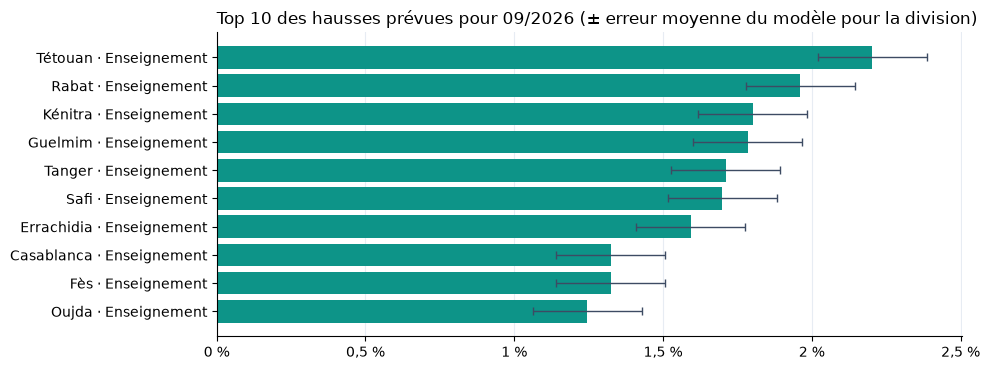

In [20]:
previsions = spark.read.parquet((GOLD / "previsions").as_posix())
top10 = previsions.filter("rang <= 10").orderBy("rang").toPandas()
erreur = par_division.set_index("code").mae_modele
mois_cible = top10.date_cible.iloc[0]
print(f"Prévision pour {mois_cible:%m/%Y}, modèle {famille_retenue} réentraîné sur toutes les données connues")

figure, axe = plt.subplots(figsize=(10, 3.8))
noms = [f"{r.ville} · {r.libelle.capitalize()}" for r in top10.itertuples()]
axe.barh(noms, top10.prediction, color=COULEURS["s1"],
         xerr=[erreur[c] for c in top10.code], error_kw={"ecolor": "#3d4b63", "capsize": 3, "linewidth": 1})
axe.invert_yaxis()
axe.xaxis.set_major_formatter(en_pourcent)
axe.set_title(f"Top 10 des hausses prévues pour {mois_cible:%m/%Y} (± erreur moyenne du modèle pour la division)", loc="left")
axe.grid(axis="y", visible=False)
figure.tight_layout()
top10[["rang", "ville", "libelle", "prediction", "glissement_annuel"]]

**Lecture.** Pour septembre 2026, les dix plus fortes hausses prévues concernent toutes **l'enseignement** :
c'est la rentrée scolaire, que le modèle a apprise des années précédentes. En tête : Tétouan (+2,20 %), Rabat, Kénitra.
Tétouan et Rabat cumulent une hausse prévue et un glissement annuel déjà au-dessus de 4 % :
ce sont les contrôles prioritaires.

#### Hausses inattendues : ce que la règle simple ne voit pas

La rentrée scolaire, tout le monde l'attend, et pour l'enseignement la règle « même mois l'an dernier » prévoit même
mieux que le modèle (0,12 contre 0,18 point d'erreur). Le décideur a surtout besoin de voir **ce que la règle simple
ne voit pas**. On définit donc la **surprise** = hausse prévue - hausse du même mois l'an dernier, et on classe
les combinaisons ville × division sur cette surprise (colonnes `surprise` et `rang_surprise` de `gold/previsions`).

L'application n'affiche que les **hausses prévues** (prévue > 0) : une baisse moins forte que l'an dernier
(Al Hoceima, restaurants et hôtels : -2,43 % prévu après -8,71 %) a une grosse surprise, mais ce n'est pas une hausse.

**Est-ce utile ?** On le mesure sur le test, comme pour le top 10 : chaque mois, part des 10 plus fortes surprises
prévues qui sont parmi les 10 plus fortes surprises réelles (cible - même mois l'an dernier), colonne
`part_top10_surprise` de `gold/metriques`. La règle « même mois l'an dernier » prévoit une surprise nulle partout :
elle n'a pas de score. La comparaison juste est la règle « mois suivant = mois courant », puis le hasard (10/216).

def part_top10_surprise(predictions, colonne):
    """Même mesure sur les « hausses inattendues » : surprise = hausse au-delà de celle du même mois l'an dernier
    (ce que la règle simple ne voit pas). Prévue : prévision - an dernier ; réelle : cible - an dernier."""
    an_dernier = F.col("variation_meme_mois_an_dernier")
    surprises = (predictions.withColumn("surprise_prevue", F.col(colonne) - an_dernier)
                 .withColumn("surprise_reelle", F.col("cible") - an_dernier))
    return part_top10(surprises, "surprise_prevue", reel="surprise_reelle")

,rang,ville,libelle,prévue (%),en 2025 (%),écart (pt)
0,1,Al Hoceima,PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES,0.23,-3.74,3.97
1,2,Tanger,TRANSPORTS,1.22,-1.54,2.76
2,3,Casablanca,TRANSPORTS,1.13,-1.60,2.74
3,4,Al Hoceima,TRANSPORTS,1.22,-1.26,2.48
4,5,Tétouan,TRANSPORTS,1.15,-1.33,2.48
5,6,Meknès,PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES,0.64,-1.16,1.80
6,7,Tétouan,PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES,0.50,-1.25,1.75
7,8,Rabat,TRANSPORTS,1.06,-0.69,1.75
8,9,Tanger,PRODUITS ALIMENTAIRES ET BOISSONS NON ALCOOLISÉES,1.06,-0.67,1.74
9,10,Kénitra,TRANSPORTS,0.86,-0.87,1.72


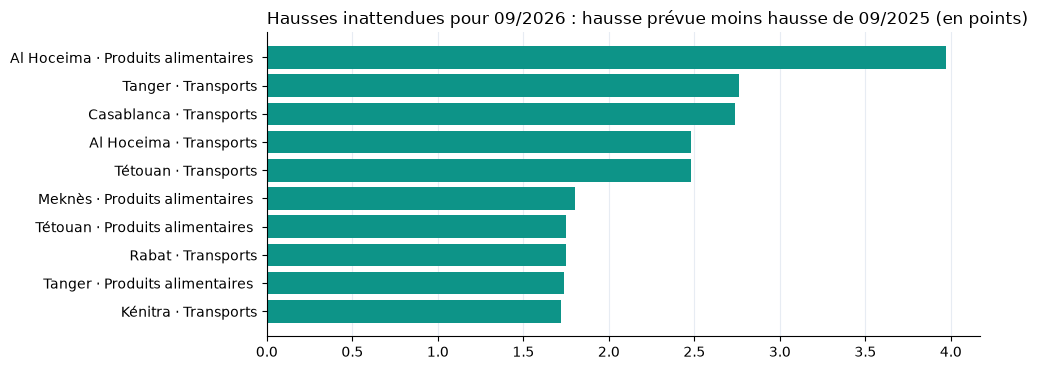

In [21]:
montrer(ml.part_top10_surprise)
surprises = (previsions.filter("rang_surprise IS NOT NULL AND prediction > 0")   # seulement les vraies hausses
             .orderBy(F.desc("surprise")).limit(10).toPandas())
surprises["rang"] = range(1, len(surprises) + 1)   # remplace le rang des plus fortes hausses
annee_precedente = mois_cible.year - 1

figure, axe = plt.subplots(figsize=(10, 3.8))
axe.barh([f"{r.ville} · {r.libelle.capitalize()[:22]}" for r in surprises.itertuples()], surprises.surprise,
         color=COULEURS["s1"])
axe.invert_yaxis()
axe.set_title(f"Hausses inattendues pour {mois_cible:%m/%Y} : hausse prévue moins hausse de {mois_cible:%m}/{annee_precedente} "
              "(en points)", loc="left")
axe.grid(axis="y", visible=False)
figure.tight_layout()
surprises[["rang", "ville", "libelle", "prediction", "variation_meme_mois_an_dernier", "surprise"]] \
    .rename(columns={"prediction": "prévue (%)", "variation_meme_mois_an_dernier": f"en {annee_precedente} (%)",
                     "surprise": "écart (pt)"}).round(2)

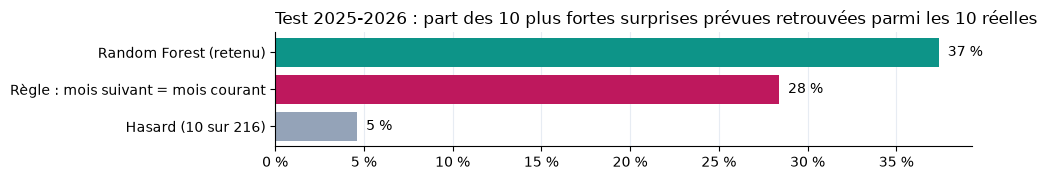

In [22]:
test_surprise = metriques.set_index("modele").part_top10_surprise
comparaison = pd.Series({
    f"{famille_retenue} (retenu)": test_surprise[famille_retenue],
    "Règle : mois suivant = mois courant": test_surprise["Naïf : mois suivant = mois courant"],
    "Hasard (10 sur 216)": 10 / 216,
})
figure, axe = plt.subplots(figsize=(10, 1.9))
axe.barh(comparaison.index, comparaison * 100, color=[COULEURS["s1"], COULEURS["s2"], COULEURS["gris"]])
axe.invert_yaxis()
for y, part in enumerate(comparaison):
    axe.text(part * 100 + 0.5, y, f"{part * 100:.0f} %", va="center")
axe.xaxis.set_major_formatter(en_pourcent)
axe.set_title("Test 2025-2026 : part des 10 plus fortes surprises prévues retrouvées parmi les 10 réelles", loc="left")
axe.grid(axis="y", visible=False)
figure.tight_layout()

**Lecture honnête.** Le top 10 des hausses inattendues de septembre 2026 fait apparaître ce que le classement brut
cachait : les **transports** (Tanger, Casablanca, Al Hoceima, Tétouan, Rabat, Kénitra) et l'**alimentation**
(Al Hoceima, Meknès, Tétouan, Tanger), dont les prix avaient baissé en septembre 2025 et devraient remonter.
Sur le test, le modèle retrouve **37 %** des 10 plus fortes surprises réelles, contre **28 %** pour la règle
« mois suivant = mois courant » et 5 % pour le hasard. Le modèle fait mieux que la règle simple, **mais le gain est
modeste**, et une partie du score est mécanique : après une chute exceptionnelle l'an dernier, presque toute valeur
de cette année la dépasse, si bien qu'une règle qui ne recopie pas l'an dernier retrouve déjà ces cas.

### 4.2 Regrouper les villes qui ont le même profil d'inflation (KMeans)

Une ligne par ville (18 villes) : le glissement annuel moyen de chacune des 12 divisions depuis 2018, **standardisé**
(sinon les divisions qui varient beaucoup, comme les transports, domineraient la distance).
Le nombre de groupes `k` (de 2 à 6) est choisi par le **score silhouette** (de -1 à 1 : plus haut = groupes mieux séparés).
Avec si peu de villes, le résultat dépendait du point de départ aléatoire : on fait **10 départs par k** et on garde
les groupes les plus compacts, sur des villes toujours triées dans le même ordre (résultat reproductible).

In [23]:
montrer(ml.kmeans)
essais_kmeans, k_retenu = ml.kmeans()
silhouette = {k: round(score, 3) for k, (score, _) in essais_kmeans.items()}
print("Silhouette par k :", silhouette, "-> k retenu :", k_retenu)

def kmeans():
    profil = spark.read.parquet((GOLD / "profil_villes").as_posix())
    divisions = [c for c in profil.columns if c != "ville"]
    # Standardiser : sinon les divisions qui varient beaucoup (transports, alimentation) dominent la distance
    preparation = Pipeline(stages=[
        VectorAssembler(inputCols=divisions, outputCol="brut"),
        StandardScaler(inputCol="brut", outputCol="features", withMean=True, withStd=True),
    ]).fit(profil)
    # Même ordre et une seule partition partout (local, Docker, Databricks) : résultat reproductible
    villes = preparation.transform(profil.orderBy("ville").coalesce(1)).cache()

    evaluateur = ClusteringEvaluator()  # score silhouette, de -1 à 1 (plus haut = groupes mieux séparés)
    essais = {}
    for k in range(2, 7):
        # Avec 18 villes, le résultat dépend du point de départ (le k retenu variait de 2 à 5 selon la graine).
        # Comme n_init dans scikit-learn : 10 départs, on garde les groupes les plus compacts (coût minimal).
        departs = [KMeans(k=k, seed=graine).fit(villes) for graine in range(INITIALISATIONS)]
        modele = min(departs, key=lambda m: m.summary.trainingCost)
        essais[k] = (evaluateur.evaluate(modele.transform(villes)), modele)
    k_retenu = max(essais, key=lambda k: essais[k][0])

    spark.createDataFrame([(k, s, k == k_retenu) for k, (s, _) in essais.items()],
                          "k INT, silhouette DOUBLE, retenu BOOLEAN") \
        .write.mode("overwrite").parquet((GOLD / "silhouette").as_posix())
    groupes = essais[k_retenu][1].transform(villes).select("ville", F.col("prediction").alias("groupe"),
                                                           *divisions)
    groupes.write.mode("overwrite").parquet((GOLD / "groupes_villes").as_posix())
    return essais, k_retenu

Silhouette par k : {2: 0.228, 3: 0.137, 4: 0.165, 5: 0.183, 6: 0.179} -> k retenu : 2


,villes
groupe,
0,"Béni Mellal, Casablanca, Dakhla, Fès, Kénitra,..."
1,"Agadir, Al Hoceima, Errachidia, Guelmim, Laâyo..."


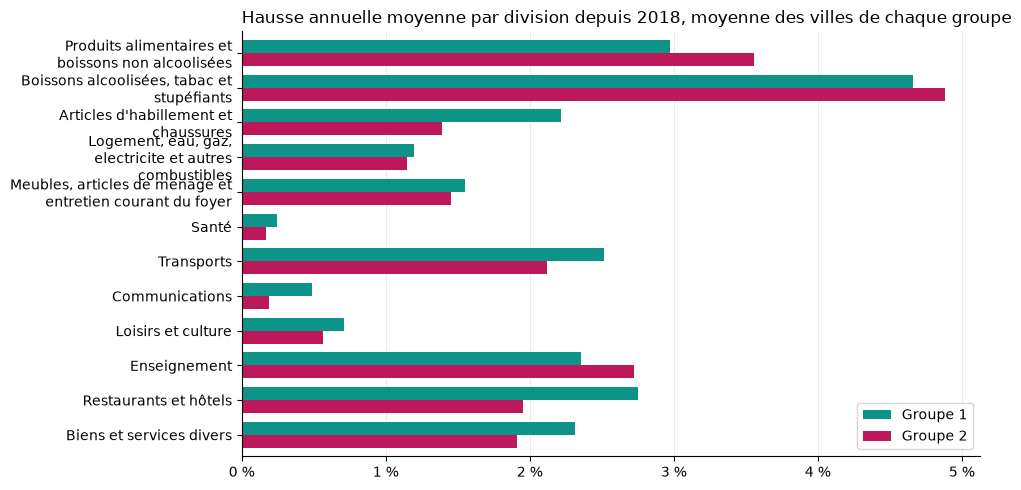

In [24]:
groupes = spark.read.parquet((GOLD / "groupes_villes").as_posix()).toPandas()
divisions = [c for c in groupes.columns if c.startswith("d")]
noms_divisions = dict(suivi.filter("code <> 'GR'").select("code", "libelle").distinct()
                      .toPandas().assign(code=lambda t: "d" + t.code).values)
display(groupes.groupby("groupe").ville.apply(lambda v: ", ".join(sorted(v))).to_frame("villes"))

profil = groupes.groupby("groupe")[divisions].mean().T
profil.index = ["\n".join(textwrap.wrap(noms_divisions[d].capitalize(), 30)) for d in profil.index]  # noms longs sur 2 lignes
axe = profil.plot.barh(figsize=(10, 5), color=[COULEURS["s1"], COULEURS["s2"], COULEURS["s3"]][:len(profil.columns)], width=0.75)
axe.invert_yaxis()
axe.xaxis.set_major_formatter(en_pourcent)
axe.legend([f"Groupe {g + 1}" for g in profil.columns], loc="lower right")
axe.set_title("Hausse annuelle moyenne par division depuis 2018, moyenne des villes de chaque groupe", loc="left")
axe.grid(axis="y", visible=False)
plt.tight_layout()

**Lecture.** Le meilleur score est obtenu pour **k = 2**, mais il reste **faible (0,23)** : les deux groupes se recouvrent
largement. On les lit comme une tendance, pas comme une frontière nette :
- groupe 1 (Béni Mellal, Casablanca, Dakhla, Fès, Kénitra, Meknès, Rabat, Safi, Settat, Tanger) :
  prix qui montent plus vite qu'ailleurs pour l'habillement, les restaurants et hôtels ;
- groupe 2 (Agadir, Al Hoceima, Errachidia, Guelmim, Laâyoune, Marrakech, Oujda, Tétouan) :
  plutôt l'alimentation, l'enseignement, l'alcool et le tabac.

Utilité : une politique de prix (aide alimentaire, contrôle des cantines scolaires…) peut viser un groupe de villes
qui partagent le même profil, plutôt que tout le pays.

## 5. Restitution : l'application décisionnelle

Le backend **FastAPI** (`api/main.py`) garde une SparkSession ouverte et répond par des requêtes **Spark SQL** sur les
tables Parquet gold (paramètres nommés, jamais de texte utilisateur dans le SQL). Le frontend **React + Recharts**
(`frontend/`) les affiche en 3 pages. Lancement : `docker compose up --build`, puis http://localhost:3000.

**Flux en direct** : la page se met à jour pendant que le producteur publie les mois (inflation nationale,
alertes par ville, santé du pipeline Spark, journal des micro-batches).

![Flux en direct](captures/flux.png)

**Prévisions** : la décision écrite en une phrase, le top 10 « ville × produit » à contrôler le mois prochain
(filtres, impression de la liste, et deux classements : « Plus fortes hausses » ou « Hausses inattendues »),
et les métriques du modèle face aux règles simples.

![Prévisions](captures/previsions.png)

**Groupes de villes** : les groupes KMeans, leur profil d'inflation et l'écart de chaque ville à la moyenne.

![Groupes de villes](captures/groupes.png)

## 6. Utilité pour la décision et limites

**Ce que le responsable public obtient.**
- Chaque mois, dès la publication du HCP, les **séries en alerte** (plus de 4 % sur un an), ville par ville :
  la moyenne nationale (-0,33 % en août 2026) cache 42 séries au-dessus du seuil.
- Un mois à l'avance, une **liste priorisée de 10 contrôles** (ville × produit), avec l'erreur attendue de chaque prévision
  et un avertissement quand une règle simple est plus fiable.
- Un second classement, les **hausses inattendues** (au-delà de celle du même mois l'an dernier) : il montre
  ce que la règle simple ne voit pas, par exemple les transports en septembre 2026 au lieu de la seule rentrée scolaire.
- Des **groupes de villes** au profil d'inflation proche, pour cibler une mesure sur plusieurs villes à la fois.

**Limites (à dire honnêtement).**
- **Précision modeste** : R² de 0,21 et MAE de 0,4 point. Le modèle classe mieux qu'une règle simple, mais de peu
  (23 % du top 10 retrouvé contre 22 %). Il oriente les contrôles, il ne remplace pas l'expertise.
- **Pas de variables externes** : prix de l'énergie, taux de change, météo (récoltes), décisions réglementaires.
  Les ajouter est la piste d'amélioration la plus prometteuse.
- **Flux simulé** : le HCP publie une fois par mois ; le producteur rejoue l'historique en accéléré.
  L'architecture (dossier surveillé, checkpoint, un micro-batch par publication) resterait la même en production.
- **KMeans sur 18 villes** : groupes peu séparés (silhouette 0,23) et sensibles au point de départ, d'où les 10 départs.
- **Volume** : 318 304 lignes tiennent sur un PC ; Spark (en mode local ici) est choisi pour le streaming
  et pour passer à l'échelle sans réécrire le code (même pipeline sur Databricks, voir `databricks/`).

In [25]:
spark.stop()
print("Pipeline complet exécuté : collecte, streaming, Spark SQL, MLlib.")

Pipeline complet exécuté : collecte, streaming, Spark SQL, MLlib.
